# Week 07 · Resampling Foundations: Bootstrap and Permutation Tests

*DS 207 · Week 07*

Many of the statistics a practitioner cares about, such as a median, a 90th percentile or a custom service-level measure, have no tidy formula for their margin of error. Resampling methods answer the same question by using the computer: they treat the one sample in hand as a small model of the population, draw from it repeatedly, and observe how much the statistic moves. This notebook develops the bootstrap and the permutation test from intuition to hand calculation to full-scale Python, and closes with a decision guide for choosing between analytic and resampling methods.

**Author:** EC Corro, built in collaboration with Claude, ChatGPT, and Gemini

## Learning Objectives

By the end of this notebook, you should be able to:

- Explain how resampling approximates a sampling distribution from a single sample, and why the sample can stand in for the population.
- Compute a bootstrap standard error by hand on a tiny sample and verify it at full scale in Python.
- Build and interpret a percentile bootstrap confidence interval, and recognise the small-sample and extreme-statistic cases in which it fails.
- Carry out a permutation test for a difference between two groups and report the p-value together with an estimate of effect size.
- Choose between an analytic method and a resampling method using a practical decision guide.

**Prerequisites:** sampling distributions, standard error and the central limit theorem (Week 6); confidence intervals and the hypothesis-testing framework (Week 7); basic NumPy and pandas.

## Business Context

Cebu Bus Rapid Transit Operations (the Authority) runs a dedicated-lane bus corridor network. Corridor 1 serves the weekday morning peak, and Carla Ouano, Service Planning Manager, has just introduced a revised dispatch schedule that staggers departures to reduce bunching. To judge it, her team intercepted 60 passengers under the current schedule and 60 under the revised schedule, recording the minutes from tap-in at the stop to boarding. The data in this notebook are simulated to reflect a plausible weekday morning peak.

Passenger waits are right-skewed: most passengers board within a few minutes, while a minority wait much longer. Carla's stakeholder question for this week is: **given only a single sample of passengers, how uncertain are our headline wait-time figures, and did the revised schedule genuinely reduce waiting?** The median and the 90th percentile are the figures the Authority reports to the city council, and neither has a textbook formula for its margin of error. Resampling supplies one.

### Subtopic 1 · Why Resampling Works

**Business Hook.** Carla asks: "We interviewed 60 passengers and the median wait was 7.85 minutes. If we had interviewed a different 60 passengers, how different could that number have been?"

## Intuition & Analogy

Imagine tasting a single spoonful from a large pot of soup. You would like to know how much one spoonful can differ from the next, but you have only one spoonful in hand. You cannot return to the pot, because in real life the pot is every weekday passenger on Corridor 1 and you only ever see a few of them.

Resampling makes a practical bargain: treat the spoonful you have as a miniature of the pot. Scoop new spoonfuls from your spoonful (putting each item back before the next draw), taste each new scoop, and see how much the results vary. The variation among those scoops is your estimate of the variation you would have seen had you gone back to the real pot.

The bargain is imperfect. A spoonful that happened to miss the chili flakes cannot produce a scoop that contains any. The resampling world is built only from what the sample contains, a point that matters in Subtopic 3.

## Theory — By Hand

A statistic such as the sample median $T = t(X_1, \dots, X_n)$ changes from sample to sample. The distribution of those changes is its **sampling distribution**, and the **standard error** (SE) is the standard deviation of that distribution:

$$
\mathrm{SE}(T) = \sqrt{\operatorname{Var}(T)}.
$$

For the sample mean we know the answer, $\mathrm{SE}(\bar X) = \sigma / \sqrt{n}$. For the median or a 90th percentile no comparable formula is available in routine use.

The **plug-in principle** supplies a workaround. The unknown population distribution $F$ is replaced by the **empirical distribution** $\hat F_n$, which places probability $1/n$ on each observed value. Drawing $n$ values from $\hat F_n$ with replacement gives a **bootstrap resample**. The relationship is

$$
\text{sample} : \text{population} \;\; \longleftrightarrow \;\; \text{resample} : \text{sample}.
$$

**Worked example.** Suppose only three passengers were observed, with waits $\{4, 6, 14\}$ minutes. Each value carries probability $1/3$. A resample of size 3 can be formed in $3^3 = 27$ equally likely ways, each with probability $1/27$. A few of them:

| Resample | Mean |
|---|---|
| (4, 4, 4) | 4.00 |
| (4, 6, 14) | 8.00 |
| (6, 6, 14) | 8.67 |
| (14, 14, 14) | 14.00 |

Averaging all 27 resample means gives exactly $8$, the sample mean. This is the first lesson: the bootstrap distribution is centred on the **sample** statistic, not on the unknown population value. What it is designed to reproduce is the **spread**, not the centre. Subtopic 2 uses this table to compute a standard error exactly.

## By Tool

The data are synthetic, so we can do something impossible in practice: compare the real sampling distribution of the median (from 5,000 fresh samples of 60 passengers) against the bootstrap distribution built from the single observed sample.

           n  mean  median    sd    p90  longest
schedule                                        
Current   60  9.53    7.85  7.27  18.14     43.2
Revised   60  6.36    5.10  4.37  14.11     20.6


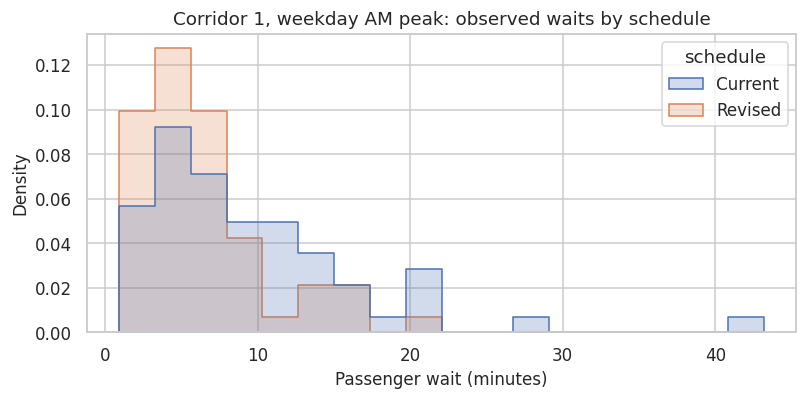

In [16]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.labelsize": 11})

# Passenger waits (minutes) at Corridor 1 stops, weekday AM peak.
# Sixty passengers were intercepted under the current dispatch schedule
# and sixty under the revised (staggered) schedule.
rng = np.random.default_rng(207)
old = np.round(rng.lognormal(np.log(6.5), 0.75, 60), 1)   # current schedule
new = np.round(rng.lognormal(np.log(5.0), 0.65, 60), 1)   # revised schedule

waits = pd.DataFrame({
    "schedule": ["Current"] * len(old) + ["Revised"] * len(new),
    "wait_min": np.concatenate([old, new]),
})

summary = (waits.groupby("schedule")["wait_min"]
           .agg(n="count", mean="mean", median="median", sd="std",
                p90=lambda s: s.quantile(0.90), longest="max")
           .round(2))
print(summary)

fig, ax = plt.subplots(figsize=(7.5, 3.8))
sns.histplot(data=waits, x="wait_min", hue="schedule", bins=18, element="step",
             stat="density", common_norm=False, ax=ax)
ax.set(xlabel="Passenger wait (minutes)", ylabel="Density",
       title="Corridor 1, weekday AM peak: observed waits by schedule")
plt.tight_layout()
plt.show()

Observed sample median:                  7.85 min
True population median (known here):     6.50 min
SE of the median, repeated sampling:     0.780 min
SE of the median, bootstrap (one sample): 1.046 min


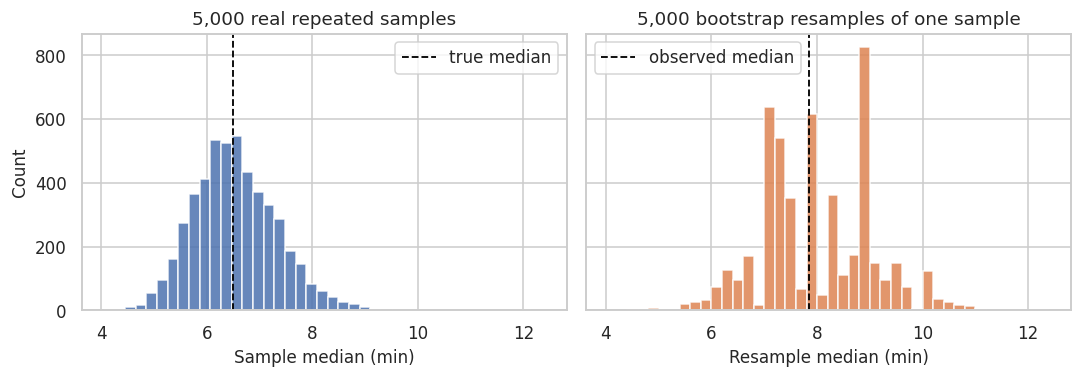

In [17]:
n = len(old)
mu_log, sigma_log = np.log(6.5), 0.75   # process that generated the current-schedule waits

# (1) What repeated sampling would give us: 5,000 fresh samples of 60 passengers each.
#     This is only possible here because the data are synthetic and the process is known.
rng_truth = np.random.default_rng(1)
fresh = rng_truth.lognormal(mu_log, sigma_log, size=(5000, n))
true_medians = np.median(fresh, axis=1)
se_true = true_medians.std(ddof=1)

# (2) What we can do in practice: resample the ONE sample we actually have.
rng_boot = np.random.default_rng(2)
idx = rng_boot.integers(0, n, size=(5000, n))          # row = one resample of 60 indices
boot_medians = np.median(old[idx], axis=1)
se_boot = boot_medians.std(ddof=1)

print(f"Observed sample median:                  {np.median(old):.2f} min")
print(f"True population median (known here):     {np.exp(mu_log):.2f} min")
print(f"SE of the median, repeated sampling:     {se_true:.3f} min")
print(f"SE of the median, bootstrap (one sample): {se_boot:.3f} min")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharex=True, sharey=True)
axes[0].hist(true_medians, bins=40, color="#4c72b0", alpha=0.85)
axes[0].axvline(np.exp(mu_log), color="black", ls="--", lw=1.2, label="true median")
axes[0].set(title="5,000 real repeated samples", xlabel="Sample median (min)", ylabel="Count")
axes[0].legend()
axes[1].hist(boot_medians, bins=40, color="#dd8452", alpha=0.85)
axes[1].axvline(np.median(old), color="black", ls="--", lw=1.2, label="observed median")
axes[1].set(title="5,000 bootstrap resamples of one sample", xlabel="Resample median (min)")
axes[1].legend()
plt.tight_layout()
plt.show()

**Reading the output.** The repeated-sampling standard error of the median is about 0.78 minutes. The bootstrap, using only the one sample, reports about 1.05 minutes. The two histograms have different centres, as the by-hand example predicted: the observed median of 7.85 minutes sits above the true median of 6.50 minutes because this particular sample happened to include several long waits (the longest is 43.2 minutes). The bootstrap inherits that quirk. Its histogram is also lumpier than the repeated-sampling one, because a resampled median can only take values built from the 60 observed waits; the lumpiness matters little for the standard error. The next cell asks whether the bootstrap SE is trustworthy on average, across many different samples.

True SE of the median:                 0.780
Average bootstrap SE over 300 samples: 0.797
Spread (SD) of the bootstrap SEs:      0.219


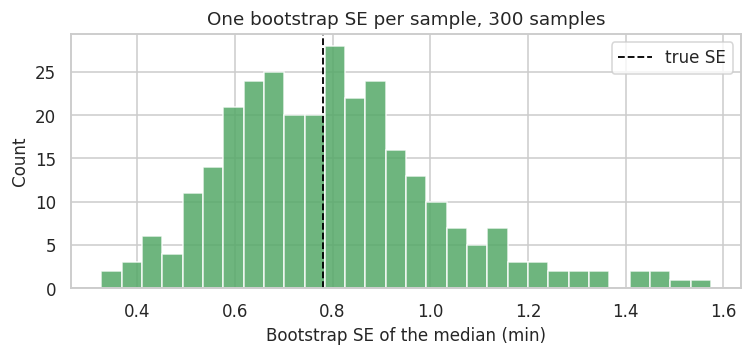

In [18]:
# Does the bootstrap SE behave well across many different samples?
# For each of 300 fresh samples, compute one bootstrap SE (500 resamples).
rng_rep = np.random.default_rng(3)
se_est = np.empty(300)
for i in range(300):
    s = rng_rep.lognormal(mu_log, sigma_log, n)
    b = np.median(s[rng_rep.integers(0, n, size=(500, n))], axis=1)
    se_est[i] = b.std(ddof=1)

print(f"True SE of the median:                 {se_true:.3f}")
print(f"Average bootstrap SE over 300 samples: {se_est.mean():.3f}")
print(f"Spread (SD) of the bootstrap SEs:      {se_est.std(ddof=1):.3f}")

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist(se_est, bins=30, color="#55a868", alpha=0.85)
ax.axvline(se_true, color="black", ls="--", lw=1.2, label="true SE")
ax.set(xlabel="Bootstrap SE of the median (min)", ylabel="Count",
       title="One bootstrap SE per sample, 300 samples")
ax.legend()
plt.tight_layout()
plt.show()

Across 300 different samples, the bootstrap SE averages about 0.80 minutes against a true value of 0.78. Individual estimates scatter (standard deviation about 0.22), so any single bootstrap SE is approximate, but the method is centred in the right place.

## Business Application

Carla can now attach a margin of error to the headline figure in the monthly council memo: a median wait of 7.9 minutes with a standard error of roughly 1 minute, instead of a bare number. Because a month-to-month movement smaller than about two standard errors (about 2 minutes) is within sampling noise at this sample size, she will not reopen the dispatch plan on the strength of a one-minute change in the median. If the council wants smaller movements to be detectable, her team must interview more passengers, since the standard error shrinks with sample size.

### Subtopic 2 · The Bootstrap Principle and Bootstrap Standard Errors

**Business Hook.** Carla asks: "What is the margin of error on the median wait, and on the 90th percentile that the council cares about most?"

## Intuition & Analogy

Write each of the 60 passengers' waits on a slip of paper and place the slips in a hat. Draw one slip, note the wait, and **put it back**. Repeat 60 times. You now hold one imitation sample of 60 passengers, in which some passengers appear twice or three times and others not at all. Compute the median of this imitation sample, then repeat the whole exercise several thousand times.

If the medians of the imitation samples barely differ, the median is a stable summary. If they swing widely, the median is fragile. The standard deviation of those thousands of medians is the **bootstrap standard error**.

## Theory — By Hand

**Algorithm.** For a statistic $\hat\theta$ computed from a sample $x_1, \dots, x_n$:

1. Draw a resample $x_1^*, \dots, x_n^*$ by sampling $n$ values from the data **with replacement**.
2. Compute the statistic $\hat\theta^*_b$ on the resample.
3. Repeat for $b = 1, \dots, B$.
4. Report the bootstrap standard error

$$
\widehat{\mathrm{SE}}_B = \sqrt{\frac{1}{B-1} \sum_{b=1}^{B} \left(\hat\theta^*_b - \bar{\theta}^*\right)^2},
\qquad \bar\theta^* = \frac{1}{B}\sum_{b=1}^{B}\hat\theta^*_b .
$$

**Exact result for the mean.** For the bootstrap mean $\bar X^*$, the variance over all possible resamples is $\hat\sigma^2 / n$, where $\hat\sigma^2 = \frac{1}{n}\sum (x_i - \bar x)^2$ uses divisor $n$.

**Worked example** with waits $\{4, 6, 14\}$, so $\bar x = 8$:

$$
\sum (x_i - \bar x)^2 = (-4)^2 + (-2)^2 + 6^2 = 16 + 4 + 36 = 56, \qquad \hat\sigma^2 = \frac{56}{3} = 18.667,
$$

$$
\mathrm{SE}_{\text{boot}}(\bar X) = \sqrt{\frac{18.667}{3}} = \sqrt{6.222} = 2.494 .
$$

The analytic standard error uses divisor $n-1$: $s^2 = 56/2 = 28$ and $s/\sqrt{n} = \sqrt{28/3} = 3.055$. The two differ by the factor $\sqrt{(n-1)/n} = 0.816$, which is negligible for $n = 60$ but not for $n = 3$.

**Exact result for the median.** Let the sorted values be $a < b < c = 4, 6, 14$. A resample of three has median $4$ when at least two of its draws equal 4, which has probability $3 (1/3)^2 (2/3) + (1/3)^3 = 7/27$. By symmetry the median is $14$ with probability $7/27$, and it is $6$ with probability $13/27$.

| Bootstrap median $m$ | Probability |
|---|---|
| 4 | 7/27 |
| 6 | 13/27 |
| 14 | 7/27 |

$$
E[m] = \frac{4(7) + 6(13) + 14(7)}{27} = \frac{204}{27} = 7.556, \qquad
E[m^2] = \frac{16(7) + 36(13) + 196(7)}{27} = \frac{1952}{27} = 72.296,
$$

$$
\operatorname{Var}(m) = 72.296 - 7.556^2 = 15.21, \qquad \mathrm{SE}_{\text{boot}}(\text{median}) = \sqrt{15.21} = 3.90 .
$$

**How many resamples?** Two sources of error are present. One is the uncertainty built into having only $n$ observations, and no value of $B$ removes it. The other is Monte Carlo noise from using a finite $B$, which does shrink as $B$ grows. A few thousand resamples is usually ample for a standard error.

## By Tool

First we reproduce the by-hand results by enumerating all 27 resamples. Then we scale up: bootstrap standard errors for the mean, the median and the 90th percentile of the 60 current-schedule waits.

In [19]:
# Exact bootstrap distribution for the three-observation sample {4, 6, 14}.
x3 = np.array([4, 6, 14])
all_resamples = np.array(list(itertools.product(x3, repeat=3)))   # 3^3 = 27 equally likely resamples
exact_means = all_resamples.mean(axis=1)
exact_medians = np.median(all_resamples, axis=1)

print("Number of equally likely resamples:", len(all_resamples))
print("Exact bootstrap SE of the mean:    ", exact_means.std(ddof=0).round(3))
print("Plug-in formula sqrt(sigma_hat^2/n):", np.sqrt(x3.var(ddof=0) / 3).round(3))
print("Analytic s/sqrt(n):                ", (x3.std(ddof=1) / np.sqrt(3)).round(3))
print()
print("Exact distribution of the bootstrap median (counts out of 27):")
print(pd.Series(exact_medians).value_counts().sort_index().to_string())
print("Exact bootstrap SE of the median:  ", exact_medians.std(ddof=0).round(3))

Number of equally likely resamples: 27
Exact bootstrap SE of the mean:     2.494
Plug-in formula sqrt(sigma_hat^2/n): 2.494
Analytic s/sqrt(n):                 3.055

Exact distribution of the bootstrap median (counts out of 27):
4.0      7
6.0     13
14.0     7
Exact bootstrap SE of the median:   3.9


The enumeration confirms the hand calculation: an exact bootstrap SE of 2.494 for the mean (matching the plug-in formula, and below the analytic 3.055), and 3.90 for the median with counts of 7, 13 and 7 out of 27.

                 estimate  bootstrap_SE  analytic_SE
statistic                                           
Mean                9.528         0.938        0.938
Median              7.850         1.057          NaN
90th percentile    18.140         2.568          NaN


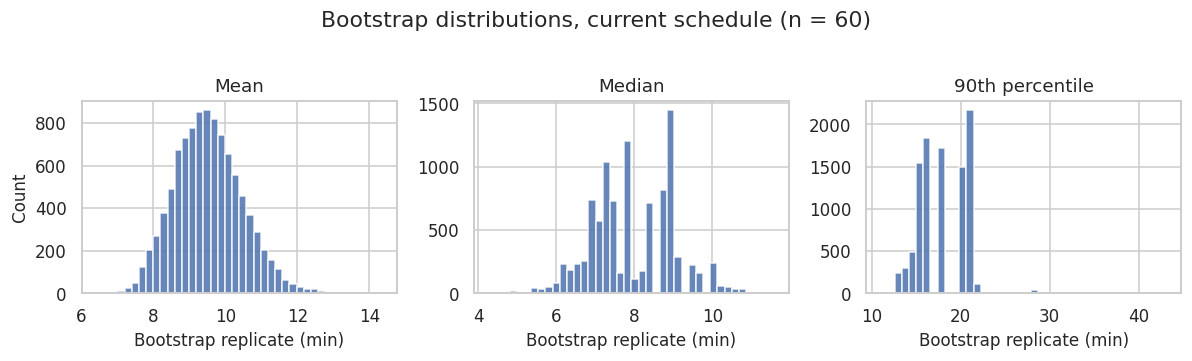

In [20]:
def bootstrap_dist(x, stat, B=10_000, seed=0):
    """Return B bootstrap replicates of `stat` computed on resamples of x."""
    r = np.random.default_rng(seed)
    idx = r.integers(0, len(x), size=(B, len(x)))
    return stat(x[idx], axis=1)

stat_funcs = {
    "Mean": np.mean,
    "Median": np.median,
    "90th percentile": lambda a, axis: np.percentile(a, 90, axis=axis),
}

rows = []
for name, f in stat_funcs.items():
    dist = bootstrap_dist(old, f, B=10_000, seed=11)
    est = f(old[np.newaxis, :], axis=1)[0]
    rows.append({"statistic": name, "estimate": est, "bootstrap_SE": dist.std(ddof=1)})
se_table = pd.DataFrame(rows).set_index("statistic").round(3)
se_table["analytic_SE"] = [round(old.std(ddof=1) / np.sqrt(len(old)), 3), np.nan, np.nan]
print(se_table)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, (name, f) in zip(axes, stat_funcs.items()):
    ax.hist(bootstrap_dist(old, f, B=10_000, seed=11), bins=40, color="#4c72b0", alpha=0.85)
    ax.set(title=name, xlabel="Bootstrap replicate (min)")
axes[0].set_ylabel("Count")
plt.suptitle("Bootstrap distributions, current schedule (n = 60)", y=1.02)
plt.tight_layout()
plt.show()

For the mean, the bootstrap SE (0.938) agrees with the analytic $s/\sqrt{n}$ (0.938), which is the reassurance we want: where a formula exists, the bootstrap reproduces it. For the median (about 1.06 minutes) and the 90th percentile (about 2.57 minutes) the bootstrap is giving us numbers that no routine formula supplies. The 90th percentile is far less stable than the median because it depends on the thin upper tail.

       run 1  run 2  run 3  run 4  run 5
50     1.137  0.964  0.964  1.146  1.138
100    0.943  0.993  0.934  1.052  1.013
250    1.026  1.150  1.072  1.050  0.998
500    1.010  1.093  1.033  1.027  1.079
1000   1.034  1.048  1.075  1.059  1.048
2500   1.062  1.059  1.037  1.048  1.044
5000   1.055  1.075  1.063  1.054  1.062
10000  1.066  1.056  1.051  1.054  1.056


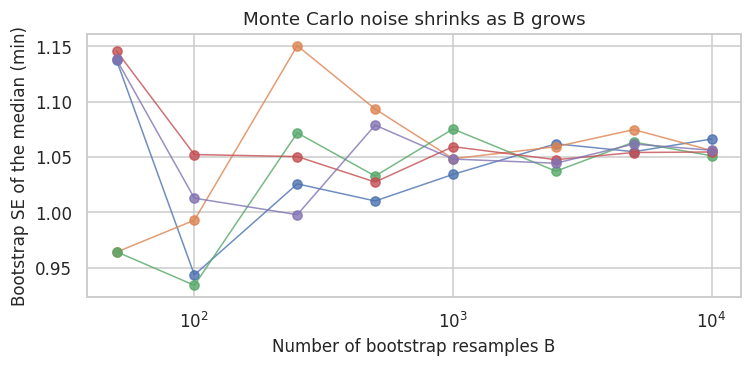

In [21]:
# How many resamples are enough? Bootstrap SE of the median against B.
B_grid = [50, 100, 250, 500, 1000, 2500, 5000, 10000]
se_by_B = pd.DataFrame(
    {f"run {k}": [bootstrap_dist(old, np.median, B=B, seed=100 * k + B).std(ddof=1) for B in B_grid]
     for k in range(1, 6)},
    index=B_grid,
)
print(se_by_B.round(3))

fig, ax = plt.subplots(figsize=(7, 3.5))
for col in se_by_B.columns:
    ax.plot(B_grid, se_by_B[col], marker="o", lw=1, alpha=0.8)
ax.set_xscale("log")
ax.set(xlabel="Number of bootstrap resamples B", ylabel="Bootstrap SE of the median (min)",
       title="Monte Carlo noise shrinks as B grows")
plt.tight_layout()
plt.show()

With $B$ between 50 and 100 the estimate wanders between about 0.93 and 1.15 minutes. Beyond $B = 2{,}500$ the five runs agree to within about 0.03, settling near 1.04 to 1.07. We use $B = 10{,}000$ throughout, which is cheap at this sample size.

## Business Application

The 90th percentile for the current schedule is 18.1 minutes with a standard error of about 2.6 minutes, so Carla should present it as "about 18 minutes, give or take 5". The median, at 7.9 minutes with a standard error of about 1.1 minutes, is a far steadier headline. She will therefore make the median the primary monthly control metric and report the 90th percentile alongside it with its uncertainty stated. A swing of 2 to 3 minutes in the 90th percentile from one month to the next should not trigger a schedule change on its own.

### Subtopic 3 · Bootstrap Confidence Intervals (Percentile Method) and When They Fail

**Business Hook.** Carla asks: "Can we give the council a range for the typical wait, and can we trust the same method for the pilot feeder stop where we have only eight passengers?"

## Intuition & Analogy

Roll a cup of dice many times, and keep the totals. The middle 95% of those totals tells you the range of outcomes to expect. The percentile bootstrap does the same with resampled statistics: shake the sample thousands of times, record the statistic each time, and report the middle 95%.

The trouble starts when the cup holds too few dice, or when you ask about the extremes. A pilot stop with eight passengers is like a photocopy of a photocopy: each generation can only reproduce what survived the previous one. If none of the eight happened to wait very long, the resampling world has no long waits to draw from, and the method cannot imagine any.

## Theory — By Hand

The **percentile interval** at confidence level $1-\alpha$ is formed from the quantiles of the bootstrap distribution:

$$
\left[\, \hat\theta^*_{(\alpha/2)},\; \hat\theta^*_{(1-\alpha/2)} \,\right],
$$

where $\hat\theta^*_{(q)}$ is the $q$-th quantile of the $B$ bootstrap replicates.

**Worked example.** The sample is $\{3, 5, 8, 24\}$ with mean $10$. Twenty bootstrap resamples are drawn, and the first three are

| Resample | Values | Mean |
|---|---|---|
| 1 | (24, 24, 24, 24) | 24.00 |
| 2 | (3, 24, 24, 5) | 14.00 |
| 3 | (3, 3, 24, 24) | 13.50 |

All 20 resample means, sorted, are

$$
4.25,\ 5.50,\ 8.25,\ 9.25,\ 10.00,\ 10.00,\ 10.00,\ 10.50,\ 10.50,\ 10.50,\ 10.75,\ 10.75,\ 12.00,\ 13.50,\ 14.00,\ 14.50,\ 14.75,\ 15.25,\ 18.75,\ 24.00 .
$$

To cover 90% of 20 values, discard the lowest one and the highest one. The interval runs from the 2nd smallest to the 19th smallest value: $[5.50,\ 18.75]$. It is lopsided around the sample mean of 10, which reflects the long right tail in the data.

**Why the method fails in small samples and for extremes.**

1. *The resampling world is bounded by the data.* A bootstrap resample can never contain a value larger than the largest observation. For the sample $\{4, 6, 14\}$, a resample contains the value 14 unless all three draws avoid it, so

$$
P(\max{}^* = \max) = 1 - \left(1 - \tfrac{1}{n}\right)^n = 1 - \left(\tfrac{2}{3}\right)^3 = \tfrac{19}{27} = 0.704,
$$

which tends to $1 - e^{-1} \approx 0.632$ as $n$ grows. For any statistic near the maximum, such as the 90th percentile at small $n$, the bootstrap distribution piles up on the observed top values.

2. *The bootstrap distribution is coarse.* For $\{4, 6, 14\}$ the bootstrap median takes only three values with probabilities $7/27 = 0.259$, $13/27$ and $7/27$. The 2.5th percentile is therefore 4 and the 97.5th is 14, so the 95% percentile interval for the median is $[4, 14]$, the full range of the data regardless of what the truth is.

3. *Skewed statistics at small $n$ undercover.* The interval tends to be too narrow, because the bootstrap SE is smaller than the analytic one (by the $\sqrt{(n-1)/n}$ factor seen earlier) and because the tail it cannot see is the tail that matters.

## By Tool

We reproduce the by-hand interval from the same resamples, confirm the maximum-probability formula, and then compute percentile intervals at full scale.

In [25]:
# Percentile interval from 20 bootstrap resamples of {3, 5, 8, 24}.
x4 = np.array([3, 5, 8, 24])
rng_hand = np.random.default_rng(13)
res20 = x4[rng_hand.integers(0, 4, size=(20, 4))]
means20 = res20.mean(axis=1)

for i in range(3):
    print(f"Resample {i + 1}: {res20[i].tolist()}  mean = {means20[i]:.2f}")
print()
print("All 20 resample means:", means20.round(2).tolist())
sorted20 = np.sort(means20)
print("Sorted:               ", sorted20.round(2).tolist())
print(f"Approximate 90% percentile interval (2nd to 19th smallest): "
      f"[{sorted20[1]:.2f}, {sorted20[18]:.2f}]")
print()

# Probability that the bootstrap maximum equals the observed maximum.
x3 = np.array([4, 6, 14])
all3 = np.array(list(itertools.product(x3, repeat=3)))
print("n = 3, P(resample max = observed max):", (all3.max(axis=1) == 14).mean().round(4),
      "| formula 1 - (1 - 1/n)^n =", round(1 - (1 - 1 / 3) ** 3, 4))
print("n = 60, formula 1 - (1 - 1/n)^n =", round(1 - (1 - 1 / 60) ** 60, 4))

Resample 1: [24, 24, 24, 24]  mean = 24.00
Resample 2: [3, 24, 24, 5]  mean = 14.00
Resample 3: [3, 3, 24, 24]  mean = 13.50

All 20 resample means: [24.0, 14.0, 13.5, 10.75, 18.75, 14.5, 10.0, 10.5, 14.75, 15.25, 9.25, 10.5, 10.5, 10.75, 10.0, 5.5, 12.0, 4.25, 10.0, 8.25]
Sorted:                [4.25, 5.5, 8.25, 9.25, 10.0, 10.0, 10.0, 10.5, 10.5, 10.5, 10.75, 10.75, 12.0, 13.5, 14.0, 14.5, 14.75, 15.25, 18.75, 24.0]
Approximate 90% percentile interval (2nd to 19th smallest): [5.50, 18.75]

n = 3, P(resample max = observed max): 0.7037 | formula 1 - (1 - 1/n)^n = 0.7037
n = 60, formula 1 - (1 - 1/n)^n = 0.6352


The code returns the same 20 means and the same interval, $[5.50, 18.75]$. It also confirms that for $n = 3$ the bootstrap maximum equals the observed maximum with probability 0.7037 (that is, $19/27$), and that for $n = 60$ the figure is still 0.6352, close to the limit of 0.632. Even at 60 observations, nearly two-thirds of resamples reproduce the observed maximum exactly.

                 estimate  ci_low  ci_high
Mean                 9.53    7.83    11.42
Median               7.85    6.10    10.10
90th percentile     18.14   13.06    21.10

SciPy percentile CI for the median: [ 6.1 10.1]
Classical t interval for the mean:   [ 7.65 11.41]


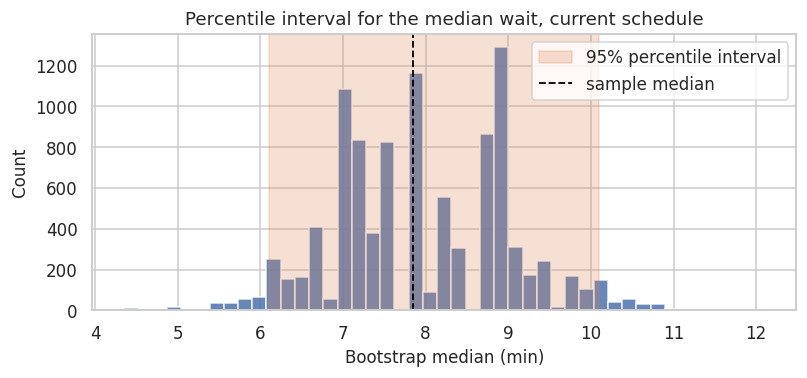

In [8]:
def percentile_ci(x, stat, conf=0.95, B=10_000, seed=0):
    dist = bootstrap_dist(x, stat, B=B, seed=seed)
    a = (1 - conf) / 2
    return np.quantile(dist, [a, 1 - a]), dist

p90 = lambda a, axis: np.percentile(a, 90, axis=axis)
results = {}
for name, f in {"Mean": np.mean, "Median": np.median, "90th percentile": p90}.items():
    ci, dist = percentile_ci(old, f, seed=21)
    results[name] = (f(old[np.newaxis, :], axis=1)[0], ci, dist)

ci_table = pd.DataFrame(
    {k: {"estimate": v[0], "ci_low": v[1][0], "ci_high": v[1][1]} for k, v in results.items()}
).T.round(2)
print(ci_table)

# Cross-check against SciPy's built-in percentile bootstrap (median)
res_sp = stats.bootstrap((old,), np.median, confidence_level=0.95, n_resamples=9999,
                         method="percentile", random_state=np.random.default_rng(5))
print("\nSciPy percentile CI for the median:",
      np.round([res_sp.confidence_interval.low, res_sp.confidence_interval.high], 2))

# Classical t interval for the mean, for comparison
t_ci = stats.t.interval(0.95, df=len(old) - 1, loc=old.mean(), scale=stats.sem(old))
print("Classical t interval for the mean:  ", np.round(t_ci, 2))

fig, ax = plt.subplots(figsize=(7.5, 3.6))
med_est, med_ci, med_dist = results["Median"]
ax.hist(med_dist, bins=45, color="#4c72b0", alpha=0.85)
ax.axvspan(med_ci[0], med_ci[1], color="#dd8452", alpha=0.25, label="95% percentile interval")
ax.axvline(med_est, color="black", ls="--", lw=1.2, label="sample median")
ax.set(xlabel="Bootstrap median (min)", ylabel="Count",
       title="Percentile interval for the median wait, current schedule")
ax.legend()
plt.tight_layout()
plt.show()

At $n = 60$ the percentile interval for the mean, 7.83 to 11.42 minutes, is close to the classical $t$ interval of 7.65 to 11.41. The interval for the median runs from 6.10 to 10.10 minutes, and SciPy's built-in routine returns the same limits. The 90th percentile has an interval of 13.06 to 21.10 minutes, noticeably wider and more lopsided than the median's.

Pilot waits (min): [1.1, 1.8, 2.3, 2.4, 3.2, 5.0, 5.6, 12.7]
Sample 90th percentile: 7.73 min
95% percentile interval: [3.20, 12.70]
Distinct values taken by the bootstrap 90th percentile: 23
Largest bootstrap value 12.70 vs largest observation 12.70
True 90th percentile of the process (known here): 17.00 min


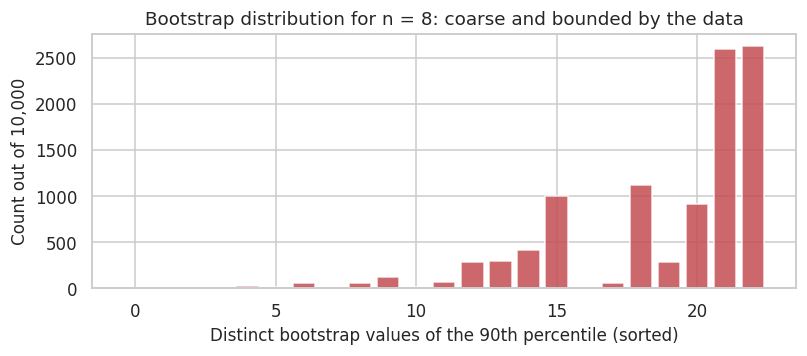

In [9]:
# A pilot feeder stop: only 8 passengers observed
pilot = np.round(np.random.default_rng(8).lognormal(np.log(6.5), 0.75, 8), 1)
print("Pilot waits (min):", np.sort(pilot).tolist())

p90_est = np.percentile(pilot, 90)
ci_p90, dist_p90 = percentile_ci(pilot, p90, seed=31)
print(f"Sample 90th percentile: {p90_est:.2f} min")
print(f"95% percentile interval: [{ci_p90[0]:.2f}, {ci_p90[1]:.2f}]")
print(f"Distinct values taken by the bootstrap 90th percentile: {len(np.unique(dist_p90))}")
print(f"Largest bootstrap value {dist_p90.max():.2f} vs largest observation {pilot.max():.2f}")

true_p90 = np.exp(mu_log + sigma_log * stats.norm.ppf(0.90))
print(f"True 90th percentile of the process (known here): {true_p90:.2f} min")

fig, ax = plt.subplots(figsize=(7.5, 3.4))
vals, counts = np.unique(np.round(dist_p90, 3), return_counts=True)
ax.bar(range(len(vals)), counts, color="#c44e52", alpha=0.85)
ax.set(xlabel="Distinct bootstrap values of the 90th percentile (sorted)", ylabel="Count out of 10,000",
       title="Bootstrap distribution for n = 8: coarse and bounded by the data")
plt.tight_layout()
plt.show()

For the eight-passenger pilot stop, the sample 90th percentile is 7.73 minutes and the 95% percentile interval is 3.20 to 12.70 minutes. The true value for this process is 17.00 minutes, well outside the interval. The bootstrap 90th percentile takes only 23 distinct values and its maximum is exactly the largest observation, 12.70 minutes. The interval looks authoritative but is not.

     Mean (t interval)  Mean (bootstrap)  Median (bootstrap)  90th pct (bootstrap)
n                                                                                 
8                 87.7              82.7                92.2                  58.2
15                87.7              84.8                89.7                  79.0
30                91.5              90.8                93.2                  86.2
60                92.5              92.0                94.8                  90.0
120               92.8              92.5                93.7                  94.0


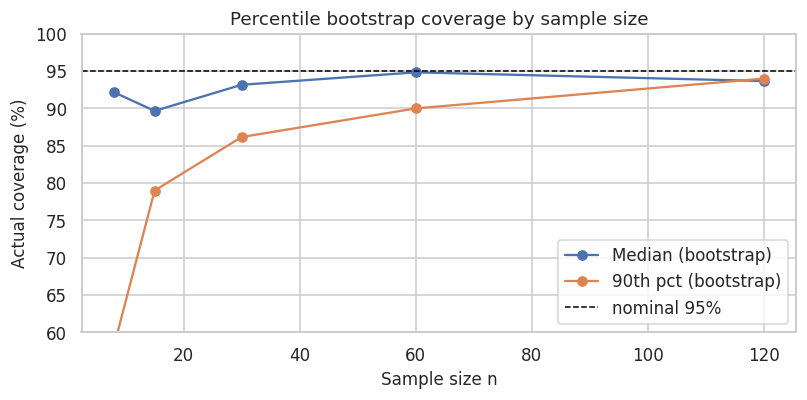

In [10]:
# Coverage study: how often does a nominal 95% interval contain the truth?
# The generating process is known, so the true values are known.
true_mean = np.exp(mu_log + sigma_log ** 2 / 2)
true_median = np.exp(mu_log)
true_p90 = np.exp(mu_log + sigma_log * stats.norm.ppf(0.90))

def covers(ci, truth):
    return ci[0] <= truth <= ci[1]

sample_sizes = [8, 15, 30, 60, 120]
n_sims, B = 600, 600
rng_cov = np.random.default_rng(41)
records = []
for m in sample_sizes:
    hit = {"Mean (t interval)": 0, "Mean (bootstrap)": 0, "Median (bootstrap)": 0, "90th pct (bootstrap)": 0}
    for _ in range(n_sims):
        s = rng_cov.lognormal(mu_log, sigma_log, m)
        res = s[rng_cov.integers(0, m, size=(B, m))]
        hit["Mean (t interval)"] += covers(stats.t.interval(0.95, m - 1, loc=s.mean(), scale=stats.sem(s)), true_mean)
        hit["Mean (bootstrap)"] += covers(np.quantile(res.mean(axis=1), [0.025, 0.975]), true_mean)
        hit["Median (bootstrap)"] += covers(np.quantile(np.median(res, axis=1), [0.025, 0.975]), true_median)
        hit["90th pct (bootstrap)"] += covers(np.quantile(np.percentile(res, 90, axis=1), [0.025, 0.975]), true_p90)
    records.append({"n": m, **{k: v / n_sims for k, v in hit.items()}})

coverage = pd.DataFrame(records).set_index("n")
print((coverage * 100).round(1).to_string())

fig, ax = plt.subplots(figsize=(7.5, 3.8))
for col in ["Median (bootstrap)", "90th pct (bootstrap)"]:
    ax.plot(coverage.index, coverage[col] * 100, marker="o", label=col)
ax.axhline(95, color="black", ls="--", lw=1, label="nominal 95%")
ax.set(xlabel="Sample size n", ylabel="Actual coverage (%)", ylim=(60, 100),
       title="Percentile bootstrap coverage by sample size")
ax.legend()
plt.tight_layout()
plt.show()

The coverage study repeats the experiment 600 times at each sample size, with the true values known. The percentile interval for the median is serviceable from about $n = 30$ (93.2% coverage against a nominal 95%). The 90th percentile is not: coverage is 58.2% at $n = 8$, 79.0% at $n = 15$ and 86.2% at $n = 30$, and it only approaches the nominal level near $n = 120$ (94.0%). The failure is worst precisely for small samples and extreme statistics.

## Business Application

For the Corridor 1 council memo, Carla can report the typical wait as "median 7.9 minutes, 95% interval 6.1 to 10.1 minutes", because the sample is large enough for the median. She should not publish a 90th-percentile range for the eight-passenger feeder stop pilot, since the interval would understate how long some riders wait. Her working rule for the Authority is to report percentile bootstrap intervals for medians once a sample reaches about 30 passengers, and to hold 90th-percentile intervals until the sample is on the order of 100 or more.

### Subtopic 4 · Permutation Tests

**Business Hook.** Carla asks: "Did the revised dispatch schedule really reduce waiting, or could a gap of this size arise just from which passengers we happened to intercept?"

## Intuition & Analogy

Write "Current" or "Revised" on a name tag for each of the 120 passengers. If the schedule makes no difference to anyone's wait, the tags are arbitrary: pinning them on in a different order should produce gaps between the two groups that are about as large as the one we saw. Shuffle the tags thousands of times, record the gap each time, and see where the real gap falls among the shuffled ones.

If the real gap is typical of shuffled gaps, luck could explain it. If it sits far out in the tail, luck is a poor explanation. No assumption about the shape of the waiting-time distribution is needed, only that the labels are exchangeable when the schedule has no effect.

## Theory — By Hand

The **null hypothesis** is that waits under the two schedules come from the same distribution, so the group labels carry no information. Choose a test statistic that reflects the question, for instance the difference in medians or the difference in means,

$$
T = t(\text{Current}) - t(\text{Revised}).
$$

The **permutation p-value** is the share of relabelings that produce a statistic at least as extreme as the observed one:

$$
p = \frac{\#\{\text{relabelings with } |T^*| \ge |T_{\text{obs}}|\}}{\#\{\text{all relabelings}\}} .
$$

When the number of relabelings is too large to list, we draw $B$ random ones and use $p = \dfrac{1 + \#\{|T^*| \ge |T_{\text{obs}}|\}}{B + 1}$, which never returns zero.

**Worked example.** Four passengers: Current $=\{10, 16\}$ and Revised $=\{5, 8\}$. The observed difference in means is

$$
T_{\text{obs}} = 13 - 6.5 = 6.5 .
$$

There are $\binom{4}{2} = 6$ ways to choose which two values carry the "Current" tag. The statistic for each:

| "Current" tag on | Other group | $T^*$ |
|---|---|---|
| {10, 16} | {5, 8} | $+6.5$ |
| {10, 5} | {16, 8} | $-4.5$ |
| {10, 8} | {16, 5} | $-1.5$ |
| {16, 5} | {10, 8} | $+1.5$ |
| {16, 8} | {10, 5} | $+4.5$ |
| {5, 8} | {10, 16} | $-6.5$ |

Only one relabeling reaches $+6.5$, so the one-sided $p = 1/6 = 0.167$. Two relabelings have $|T^*| \ge 6.5$, so the two-sided $p = 2/6 = 0.333$.

With two passengers per group the smallest possible p-value is $1/6$ (one-sided), so no result could ever be declared significant at the 5% level. A permutation test has no magic: the number of distinct relabelings caps the evidence the data can supply.

## By Tool

First the exact enumeration of the four-passenger example, then the full-scale test on the 60 plus 60 observed waits. The full-scale test uses 10,000 random relabelings, once with the difference in means and once with the difference in medians.

In [29]:
# Exact permutation test for the four-observation example.
current_small = np.array([10, 16])
revised_small = np.array([5, 8])
pooled4 = np.concatenate([current_small, revised_small])
obs_diff = current_small.mean() - revised_small.mean()

diffs = []
for combo in itertools.combinations(range(4), 2):      # which two values are labelled "Current"
    cur = pooled4[list(combo)]
    rev = pooled4[[i for i in range(4) if i not in combo]]
    diffs.append(cur.mean() - rev.mean())

diffs = np.array(diffs)
print("Observed difference (Current - Revised):", obs_diff)
print("All 6 relabelled differences:", diffs.tolist())
print("One-sided p (diff >= observed):", (diffs >= obs_diff).mean().round(4))
print("Two-sided p (|diff| >= |observed|):", (np.abs(diffs) >= abs(obs_diff)).mean().round(4))

Observed difference (Current - Revised): 6.5
All 6 relabelled differences: [6.5, -4.5, -1.5, 1.5, 4.5, -6.5]
One-sided p (diff >= observed): 0.1667
Two-sided p (|diff| >= |observed|): 0.3333


The enumeration reproduces the table: one-sided $p = 0.1667$ and two-sided $p = 0.3333$.

                       observed  p_two_sided  p_one_sided
Difference in means      3.1717       0.0035       0.0020
Difference in medians    2.7500       0.0167       0.0088


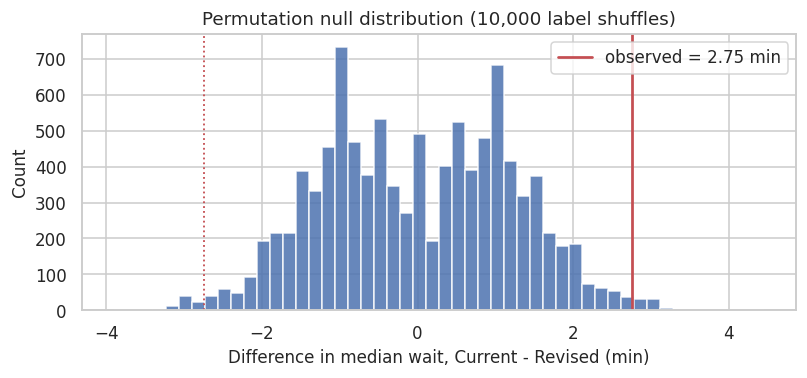

In [31]:
def perm_null(a, b, stat, B=10_000, seed=0):
    """Null distribution of stat(a) - stat(b) obtained by shuffling group labels."""
    r = np.random.default_rng(seed)
    pooled = np.concatenate([a, b])
    order = np.argsort(r.random((B, len(pooled))), axis=1)   # B independent shuffles
    shuffled = pooled[order]
    return stat(shuffled[:, :len(a)], axis=1) - stat(shuffled[:, len(a):], axis=1)

def perm_pvalue(obs, null, alternative="two-sided"):
    B = len(null)
    if alternative == "two-sided":
        extreme = np.sum(np.abs(null) >= abs(obs) - 1e-12)
    else:                                   # "greater": Current is slower than Revised
        extreme = np.sum(null >= obs - 1e-12)
    return (extreme + 1) / (B + 1)

tests = {}
for name, f in {"Difference in means": np.mean, "Difference in medians": np.median}.items():
    obs = f(old[np.newaxis, :], axis=1)[0] - f(new[np.newaxis, :], axis=1)[0]
    null = perm_null(old, new, f, B=10_000, seed=51)
    tests[name] = (obs, null, perm_pvalue(obs, null), perm_pvalue(obs, null, "greater"))

perm_table = pd.DataFrame(
    {k: {"observed": v[0], "p_two_sided": v[2], "p_one_sided": v[3]} for k, v in tests.items()}
).T.round(4)
print(perm_table)

obs_med, null_med, _, _ = tests["Difference in medians"]
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.hist(null_med, bins=50, color="#4c72b0", alpha=0.85)
ax.axvline(obs_med, color="#c44e52", lw=1.8, label=f"observed = {obs_med:.2f} min")
ax.axvline(-obs_med, color="#c44e52", lw=1.2, ls=":")
ax.set(xlabel="Difference in median wait, Current - Revised (min)", ylabel="Count",
       title="Permutation null distribution (10,000 label shuffles)")
ax.legend()
plt.tight_layout()
plt.show()

The median wait under the current schedule is 7.85 minutes against 5.10 minutes under the revised schedule, a difference of 2.75 minutes. Among 10,000 random relabelings, a gap this large in either direction occurs with probability about 0.017 (two-sided) and 0.009 (one-sided). The difference in means (3.17 minutes) is even more extreme, with a two-sided p-value of about 0.004. The null histogram is centred at zero and symmetric, as it should be (its lumpy shape reflects the limited set of values a median of 60 observations can take), and the observed gap sits in its right tail.

In [32]:
# Cross-check with SciPy's permutation_test, Welch t-test and Mann-Whitney U
def diff_median(x, y, axis=-1):
    return np.median(x, axis=axis) - np.median(y, axis=axis)

sp = stats.permutation_test((old, new), diff_median, permutation_type="independent",
                            vectorized=True, n_resamples=9999, alternative="two-sided",
                            random_state=np.random.default_rng(61))
print(f"SciPy permutation test (median diff): statistic = {sp.statistic:.2f}, p = {sp.pvalue:.4f}")

welch = stats.ttest_ind(old, new, equal_var=False)
print(f"Welch t-test (mean diff):             t = {welch.statistic:.2f}, p = {welch.pvalue:.4f}")
mw = stats.mannwhitneyu(old, new, alternative="two-sided")
print(f"Mann-Whitney U:                       U = {mw.statistic:.0f}, p = {mw.pvalue:.4f}")

# Bootstrap CI for the size of the improvement (resample each schedule separately)
rng_d = np.random.default_rng(71)
B = 10_000
b_old = np.median(old[rng_d.integers(0, len(old), size=(B, len(old)))], axis=1)
b_new = np.median(new[rng_d.integers(0, len(new), size=(B, len(new)))], axis=1)
gap = b_old - b_new
lo, hi = np.quantile(gap, [0.025, 0.975])
print(f"Bootstrap 95% CI for the median improvement: [{lo:.2f}, {hi:.2f}] min")

SciPy permutation test (median diff): statistic = 2.75, p = 0.0150
Welch t-test (mean diff):             t = 2.90, p = 0.0047
Mann-Whitney U:                       U = 2322, p = 0.0062
Bootstrap 95% CI for the median improvement: [0.30, 5.35] min


The cross-checks agree in direction and rough magnitude. SciPy's permutation routine gives $p = 0.0150$ for the median difference. The Welch $t$-test gives $p = 0.0047$ and the Mann-Whitney test $p = 0.0062$. These are different tests of different statistics, so the p-values need not match, but all point the same way.

A p-value says whether a difference is plausibly luck; it does not say how large the difference is. The last line bootstraps each schedule separately to obtain a 95% interval for the median improvement: 0.30 to 5.35 minutes. The improvement is real but its size is uncertain, from barely noticeable to several minutes.

## Business Application

Carla's evidence supports the revised schedule: the median wait fell by an estimated 2.75 minutes, a gap unlikely to be luck (permutation $p \approx 0.017$), though the plausible size of the improvement ranges from about 0.3 to 5.4 minutes. She will extend the revised schedule to the pilots on Corridors 2 and 3 and report both the p-value and the interval to the council. She will also confirm that the two sample periods were comparable (no rain event, school break or special event on one side only), because the test is valid only if the labels are exchangeable under the null. Since a lower median does not guarantee a shorter tail, she will keep tracking the 90th percentile.

### Subtopic 5 · Choosing Between Analytic and Resampling Methods

**Business Hook.** Carla's analysts ask: "Should we default to a $t$-test, or bootstrap everything? What is the Authority's standard?"

## Intuition & Analogy

A formula is like a ready-made template cut for a standard job: quick to apply, easy to audit, and reliable when the job matches the template. Resampling is like building a custom jig for an unusual job: flexible, but slower, and its quality depends on the material you feed it.

Neither tool repairs bad material. If the sample is unrepresentative, too small, or collected in a way that links observations together, both the formula and the resampling will give confident answers to the wrong question. The choice of method matters less than the questions you ask of the data before you choose.

## Theory — By Hand

We compare the two families on the smallest case, $\{4, 6, 14\}$, with $\bar x = 8$ and $s/\sqrt{n} = 3.055$.

**Analytic interval.** With $n - 1 = 2$ degrees of freedom the 97.5th percentile of the $t$ distribution is $4.303$, so

$$
8 \pm 4.303 \times 3.055 = 8 \pm 13.15 = [-5.15,\ 21.15],
$$

a width of about 26.3 minutes. It is absurdly wide, and it even dips below zero, but it honestly reflects how little three observations tell us.

**Bootstrap percentile interval.** Of the 27 resample means, the value 4 has probability $1/27 = 0.037$ and the value 14 has probability $1/27$. The 2.5th and 97.5th percentiles are therefore 4 and 14, giving $[4, 14]$ with width 10.

The bootstrap interval is less than half as wide and cannot leave the range of the data. Here the analytic method is the more honest one. This is not a general victory for formulas; it shows that at very small $n$ the bootstrap cannot manufacture information the sample lacks.

**Decision guide.**

| Situation | Preferred approach | Reason |
|---|---|---|
| Mean, moderate to large $n$, no extreme skew | Analytic ($t$ interval, Welch test), bootstrap as a cross-check | Formula is accurate, fast and easy to audit |
| Median | Bootstrap, or the order-statistic interval | Standard error has no simple formula; the two methods agree closely at moderate $n$ |
| 90th percentile, ratios, trimmed means, custom KPIs | Bootstrap, if $n$ is large (roughly 100 or more for a 90th percentile) | No routine formula; reliable only when the sample covers the tail |
| Maximum, minimum, range | Neither bootstrap nor classical formulas; use extreme-value methods or more data | Bootstrap reproduces the observed maximum about 63% of the time |
| Two groups, doubtful distributional assumptions or a custom statistic | Permutation test | Needs only exchangeability of labels under the null |
| Randomised experiment | Permutation test | Randomisation itself justifies the shuffling |
| Observational comparison | Permutation test with the exchangeability assumption argued explicitly | Systematic differences between groups break the null |
| Dependent data (repeated waits at one stop, buses on the same trip) | Cluster or block resampling, not simple resampling | Independent resampling understates variability |
| Very small $n$ (below about 15) | Neither is reliable; collect more data or transform the variable | Both undercover under skew |

Three screening questions precede the choice. Is there a trustworthy formula for this statistic? Is the sample large enough to include the part of the distribution the statistic depends on? Are the observations independent, or at least exchangeable?

## By Tool

The coverage study from Subtopic 3 already contains the evidence for the mean: we can compare the classical $t$ interval with the percentile bootstrap on the same simulated samples.

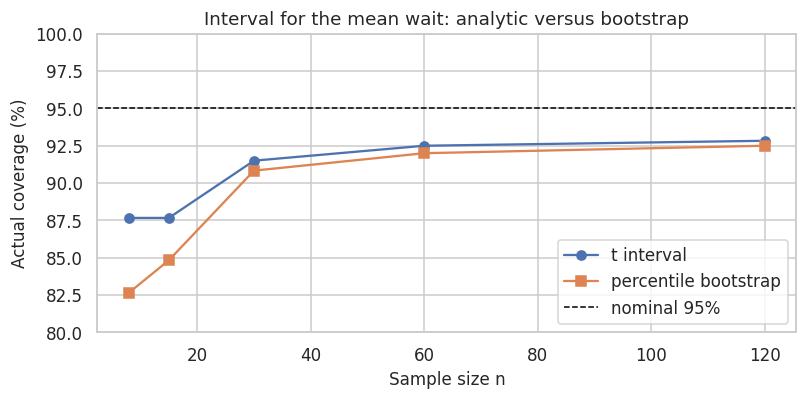

     Mean (t interval)  Mean (bootstrap)
n                                       
8                 87.7              82.7
15                87.7              84.8
30                91.5              90.8
60                92.5              92.0
120               92.8              92.5


In [33]:
# Reuse the coverage study: analytic t interval versus bootstrap for the mean
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(coverage.index, coverage["Mean (t interval)"] * 100, marker="o", label="t interval")
ax.plot(coverage.index, coverage["Mean (bootstrap)"] * 100, marker="s", label="percentile bootstrap")
ax.axhline(95, color="black", ls="--", lw=1, label="nominal 95%")
ax.set(xlabel="Sample size n", ylabel="Actual coverage (%)", ylim=(80, 100),
       title="Interval for the mean wait: analytic versus bootstrap")
ax.legend()
plt.tight_layout()
plt.show()

print((coverage[["Mean (t interval)", "Mean (bootstrap)"]] * 100).round(1).to_string())

Coverage for the mean is below the nominal 95% for both methods when the sample is small and the distribution is skewed. The $t$ interval reaches 87.7% at $n = 8$ and 92.8% at $n = 120$; the percentile bootstrap is lower at every size, by about five points at $n = 8$ (82.7%) and by less than one point from $n = 30$ onward (92.5% at $n = 120$). The bootstrap does not rescue a small, skewed sample. A transformation such as the logarithm, or a larger sample, is the more effective remedy.

We now apply both families side by side to the 60 revised-schedule waits.

In [34]:
# Applying both families of methods to the revised-schedule sample (n = 60)
m = len(new)

# Mean: analytic t interval and bootstrap percentile interval
t_lo, t_hi = stats.t.interval(0.95, m - 1, loc=new.mean(), scale=stats.sem(new))
(b_lo, b_hi), _ = percentile_ci(new, np.mean, seed=81)

# Median: distribution-free interval from order statistics, and bootstrap
srt = np.sort(new)
j = int(stats.binom.ppf(0.025, m, 0.5))             # rank of the lower limit
os_lo, os_hi = srt[j - 1], srt[m - j]               # symmetric upper rank
(bm_lo, bm_hi), _ = percentile_ci(new, np.median, seed=82)

# 90th percentile: no routine closed form -- bootstrap only
(bp_lo, bp_hi), _ = percentile_ci(new, p90, seed=83)

guide = pd.DataFrame(
    [
        ["Mean", "t interval", t_lo, t_hi, "Percentile bootstrap", b_lo, b_hi],
        ["Median", "Order-statistic (binomial)", os_lo, os_hi, "Percentile bootstrap", bm_lo, bm_hi],
        ["90th percentile", "None in routine use", np.nan, np.nan, "Percentile bootstrap", bp_lo, bp_hi],
    ],
    columns=["statistic", "analytic method", "analytic low", "analytic high",
             "resampling method", "boot low", "boot high"],
).set_index("statistic").round(2)
print(guide.to_string())

                            analytic method  analytic low  analytic high     resampling method  boot low  boot high
statistic                                                                                                          
Mean                             t interval          5.23           7.49  Percentile bootstrap      5.30       7.48
Median           Order-statistic (binomial)          3.90           7.10  Percentile bootstrap      4.10       6.90
90th percentile         None in routine use           NaN            NaN  Percentile bootstrap      8.36      16.20


The methods agree where both exist. For the mean, the $t$ interval is 5.23 to 7.49 minutes and the bootstrap interval is 5.30 to 7.48. For the median, the distribution-free interval based on order statistics is 3.90 to 7.10 minutes and the bootstrap interval is 4.10 to 6.90, so a closed-form alternative does exist even for the median. For the 90th percentile only the bootstrap is available, giving 8.36 to 16.20 minutes. Agreement between two methods is useful evidence that neither is misleading; disagreement is a signal to look at the data more closely.

## Business Application

Carla will issue a one-page reporting standard for service metrics. Means are reported with $t$ intervals and cross-checked by bootstrap. Medians and 90th percentiles are reported with bootstrap intervals, the latter only when the sample reaches about 100 passengers. Comparisons between schedules or stops use a permutation test together with an interval for the size of the difference. Any figure based on fewer than 30 passengers is labelled provisional and is not published as a service standard. The guide gives her analysts a defensible default and tells them when to stop and ask for more data.

## Key Takeaways

**Subtopic 1 · Why resampling works**
- The sampling distribution describes how a statistic varies across samples; resampling approximates it by sampling from the sample.
- The plug-in principle replaces the population distribution $F$ with the empirical distribution $\hat F_n$.
- The bootstrap distribution is centred on the sample statistic, not the truth; it is meant to reproduce the spread.

**Subtopic 2 · The bootstrap principle and standard errors**
- Resample with replacement, recompute the statistic, repeat $B$ times, take the standard deviation.
- For the mean, the bootstrap SE equals $\hat\sigma/\sqrt{n}$ (divisor $n$); it reproduces the analytic result.
- A few thousand resamples suffice; extra resamples reduce Monte Carlo noise, not sampling uncertainty.

**Subtopic 3 · Percentile intervals and their failures**
- Percentile interval: the $\alpha/2$ and $1-\alpha/2$ quantiles of the bootstrap replicates.
- A resample cannot exceed the observed maximum; the bootstrap maximum equals it with probability $1-(1-1/n)^n$ (about 63%).
- Intervals fail for tiny samples and extreme statistics: in the simulation the 90th percentile covered 58% at $n=8$ and reached nominal coverage only near $n=120$.

**Subtopic 4 · Permutation tests**
- Under the null the group labels are exchangeable; shuffle them to build the null distribution of the statistic.
- $p = (1 + \#\{|T^*| \ge |T_{\text{obs}}|\})/(B+1)$; the number of distinct relabelings caps the smallest attainable p-value.
- Report the p-value together with an interval for the effect size.

**Subtopic 5 · Choosing a method**
- Prefer an analytic method when a trustworthy formula exists; use the bootstrap as a cross-check or when none does.
- Neither family rescues very small, skewed or dependent samples.
- Screen first: is there a formula, does the sample cover the relevant tail, and are observations independent or exchangeable?

## References

DiCiccio, T. J., & Efron, B. (1996). Bootstrap confidence intervals. *Statistical Science, 11*(3), 189-228.

Davison, A. C., & Hinkley, D. V. (1997). *Bootstrap methods and their application*. Cambridge University Press.

Efron, B. (1979). Bootstrap methods: Another look at the jackknife. *The Annals of Statistics, 7*(1), 1-26.

Efron, B., & Tibshirani, R. J. (1993). *An introduction to the bootstrap*. Chapman & Hall/CRC.

Ernst, M. D. (2004). Permutation methods: A basis for exact inference. *Statistical Science, 19*(4), 676-685.

Good, P. I. (2005). *Permutation, parametric, and bootstrap tests of hypotheses* (3rd ed.). Springer.

Hesterberg, T. C. (2015). What teachers should know about the bootstrap: Resampling in the undergraduate statistics curriculum. *The American Statistician, 69*(4), 371-386.

Virtanen, P., Gommers, R., Oliphant, T. E., et al. (2020). SciPy 1.0: Fundamental algorithms for scientific computing in Python. *Nature Methods, 17*(3), 261-272.

Wasserman, L. (2004). *All of statistics: A concise course in statistical inference*. Springer.